Veronica Tarallo (matricola 945490) \
Corso: Matematica Numerica per il Machine Learning \
Docente: Franco Dassi

## Classificazione Supervisionata: Dataset `cycle_gan/horse2zebra`

In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import os
import random


print("Tutto importato correttamente!")

Tutto importato correttamente!


In [5]:
def initializeSeed():
  seed = 42
  os.environ['PYTHONHASHSEED'] = str(seed)
  random.seed(seed)
  np.random.seed(seed)
  tf.keras.utils.set_random_seed(seed)
  tf.config.experimental.enable_op_determinism()

#initializeSeed()

In [6]:
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split

# Carichiamo tutto il dataset unito in memoria
images, labels = tfds.as_numpy(tfds.load(
    'cycle_gan/horse2zebra',
    split='trainA+trainB+testA+testB',
    batch_size=-1,
    as_supervised=True,
))

In [7]:
# Primo split (Isoliamo il 10% per il Test finale)
# Il restante 90% lo chiamiamo immTrainAndVal/tagTrainAndVal, che useremo nel passo successivo.
immTrainAndVal, immTest, tagTrainAndVal, tagTest = train_test_split(
    images, labels, 
    test_size=0.10,          # 10% al Test finale
    stratify=labels, 
    shuffle=True, 
    random_state=42
)

# Secondo split (Isoliamo il 10% dal rimanente 90% per la Validazione)
immTrain, immVal, tagTrain, tagVal = train_test_split(
    immTrainAndVal, tagTrainAndVal, 
    test_size=1./9.,         # Prende 1/9 del rimanente 90% (che è 10% del totale)
    stratify=tagTrainAndVal, 
    shuffle=True, 
    random_state=42
)

# Verifichiamo le dimensioni dei set
print(f"Dimensione totale del dataset (100%): {labels.shape[0]}")
print(f"Dimensione del training set    (80%): {tagTrain.shape[0]}")
print(f"Dimensione del validation set  (10%): {tagVal.shape[0]}")
print(f"Dimensione del test set        (10%): {tagTest.shape[0]}\n")

# Verifichiamo che lo shuffle sia avvenuto correttamente, stampando le prime 10 etichette di ciascun set
print(f"First 10 shuffled labels of train:       ", tagTrain[:10])
print(f"First 10 shuffled labels of validation:  ", tagVal[:10])
print(f"First 10 shuffled labels of test:        ", tagTest[:10])

Dimensione totale del dataset (100%): 2661
Dimensione del training set    (80%): 2128
Dimensione del validation set  (10%): 266
Dimensione del test set        (10%): 267

First 10 shuffled labels of train:        [0 0 1 0 1 0 1 1 1 0]
First 10 shuffled labels of validation:   [0 1 1 0 1 1 0 0 1 1]
First 10 shuffled labels of test:         [0 0 1 0 0 1 0 1 1 0]


## Analisi Preliminare del Dataset (`cycle_gan/horse2zebra`)

Dopo aver caricato i dati ed averli suddivisi in Train/Validation/Test, ho analizzato le caratteristiche del set di addestramento (`immTrain`) per guidare la progettazione della rete neurale.

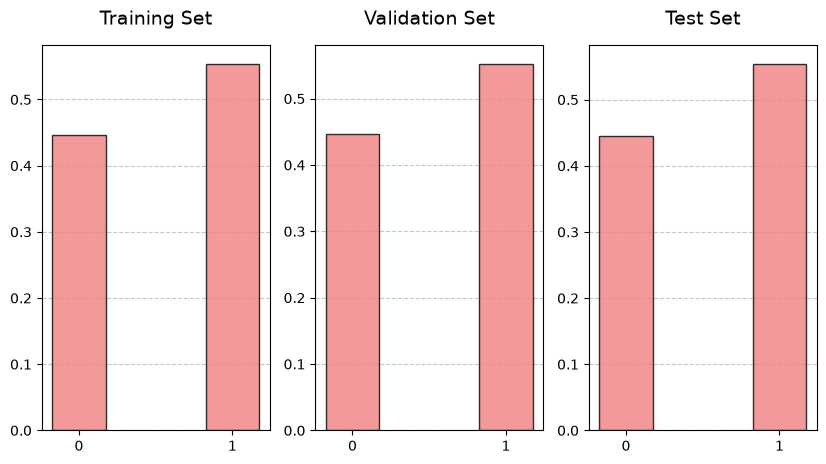

In [8]:
# Funzione che visualizza la distribuzione delle classi
def showClasses(tagToConsider, ax, titleGraph):
    labels, counts = np.unique(tagToConsider, return_counts=True)
    proportions = counts / len(tagToConsider)
    x = np.arange(len(labels))
    width = 0.35

    ax.bar(x, proportions, width, color='lightcoral', edgecolor='black', alpha=0.8)
    ax.set_title(titleGraph, fontsize=14, pad=15)
    ax.set_xticks(x)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.set_axisbelow(True)

# Visualizziamo la distribuzione delle classi nei tre set
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 5))

showClasses(tagTrain, ax1, "Training Set")
showClasses(tagVal,   ax2, "Validation Set")
showClasses(tagTest,  ax3, "Test Set")

plt.show()


---

### 1. Bilanciamento delle Classi (Cavalli vs. Zebre)
Il dataset presenta una distribuzione delle classi ragionevolmente bilanciata. Gli istogrammi confermano che la proporzione originale tra cavalli e zebre è stata preservata in tutti e tre gli split (`immTrain`, `immVal`, `immTest`). 

Dunque abbiamo che:
1. Grazie al mantenimento delle proporzioni (ottenuto tramite il parametro `stratify` in fase di split), il modello non avrà bias verso una classe maggioritaria durante l'addestramento.
2. Essendo le classi ben distribuite, l'`accuracy` (Accuratezza) sarà una metrica statisticamente solida e affidabile per valutare le performance finali della rete, dunque la utilizziamo come strategia di valutazione della bontà nei primi modelli. Nel modello finale vedremo poi anche altre metriche (Precision, Recall e Confusion Matrix).

---

In [9]:
# CONTROLLO DELLE DIMENSIONI (RISOLUZIONE)
# Isoliamo le dimensioni uniche delle immagini nel training set
# set() crea una collezione di elementi unici dell'oggetto che gli viene passato
dimensioni_uniche = set(img.shape for img in immTrain)


print("--- ANALISI DELLE DIMENSIONI ---")
print(f"Numero di risoluzioni diverse trovate: {len(dimensioni_uniche)}")
print("Risoluzioni presenti nel dataset:")
for dim in dimensioni_uniche:
    print(f" - {dim}  (Altezza: {dim[0]}px, Larghezza: {dim[1]}px, Canali colore: {dim[2]})\n")

# CONTROLLO DEL RANGE DEI PIXEL
val_min = immTrain.min()
val_max = immTrain.max()

print("--- ANALISI DEI PIXEL ---")
print(f"Valore minimo di un pixel: {val_min}")
print(f"Valore massimo di un pixel: {val_max}")

--- ANALISI DELLE DIMENSIONI ---
Numero di risoluzioni diverse trovate: 1
Risoluzioni presenti nel dataset:
 - (256, 256, 3)  (Altezza: 256px, Larghezza: 256px, Canali colore: 3)

--- ANALISI DEI PIXEL ---
Valore minimo di un pixel: 0
Valore massimo di un pixel: 255



---

### 2. Risoluzione delle Immagini

Da questo controllo abbiamo trovato che vi è 1 solo tipo di risoluzioni, più precisamente con Dimensione = `(256, 256, 3)`.

Dunque il dataset risulta perfettamente omogeneo e già standardizzato all'origine. Tutte le immagini presentano la stessa altezza (256px), larghezza (256px) e 3 canali di colore (RGB).

 Non è quindi necessario introdurre uno strato di ridimensionamento (`Resizing`) nel blocco di preprocessing. L'`input_shape` del primo strato della rete sarà impostato rigidamente a `(256, 256, 3)`.

---

### 3. Range dei Pixel
Dall'analisi dei pixel abbiamo trovato: Valore Minimo = `0`; Valore Massimo = `255`.

Le immagini sono quindi codificate nel formato con numeri interi che variano da 0 (nero) a 255 (bianco puro). 
Poichè le reti neurali faticano a convergere efficientemente con input numerici di questa scala (rischio di instabilità dei gradienti) sarà importante effettuare una normalizzazione. Verrà inserito uno strato di `layers.Rescaling(1./255)` come primissimo livello del modello per convertire i pixel nel range decimale `[0.0, 1.0]`.

---

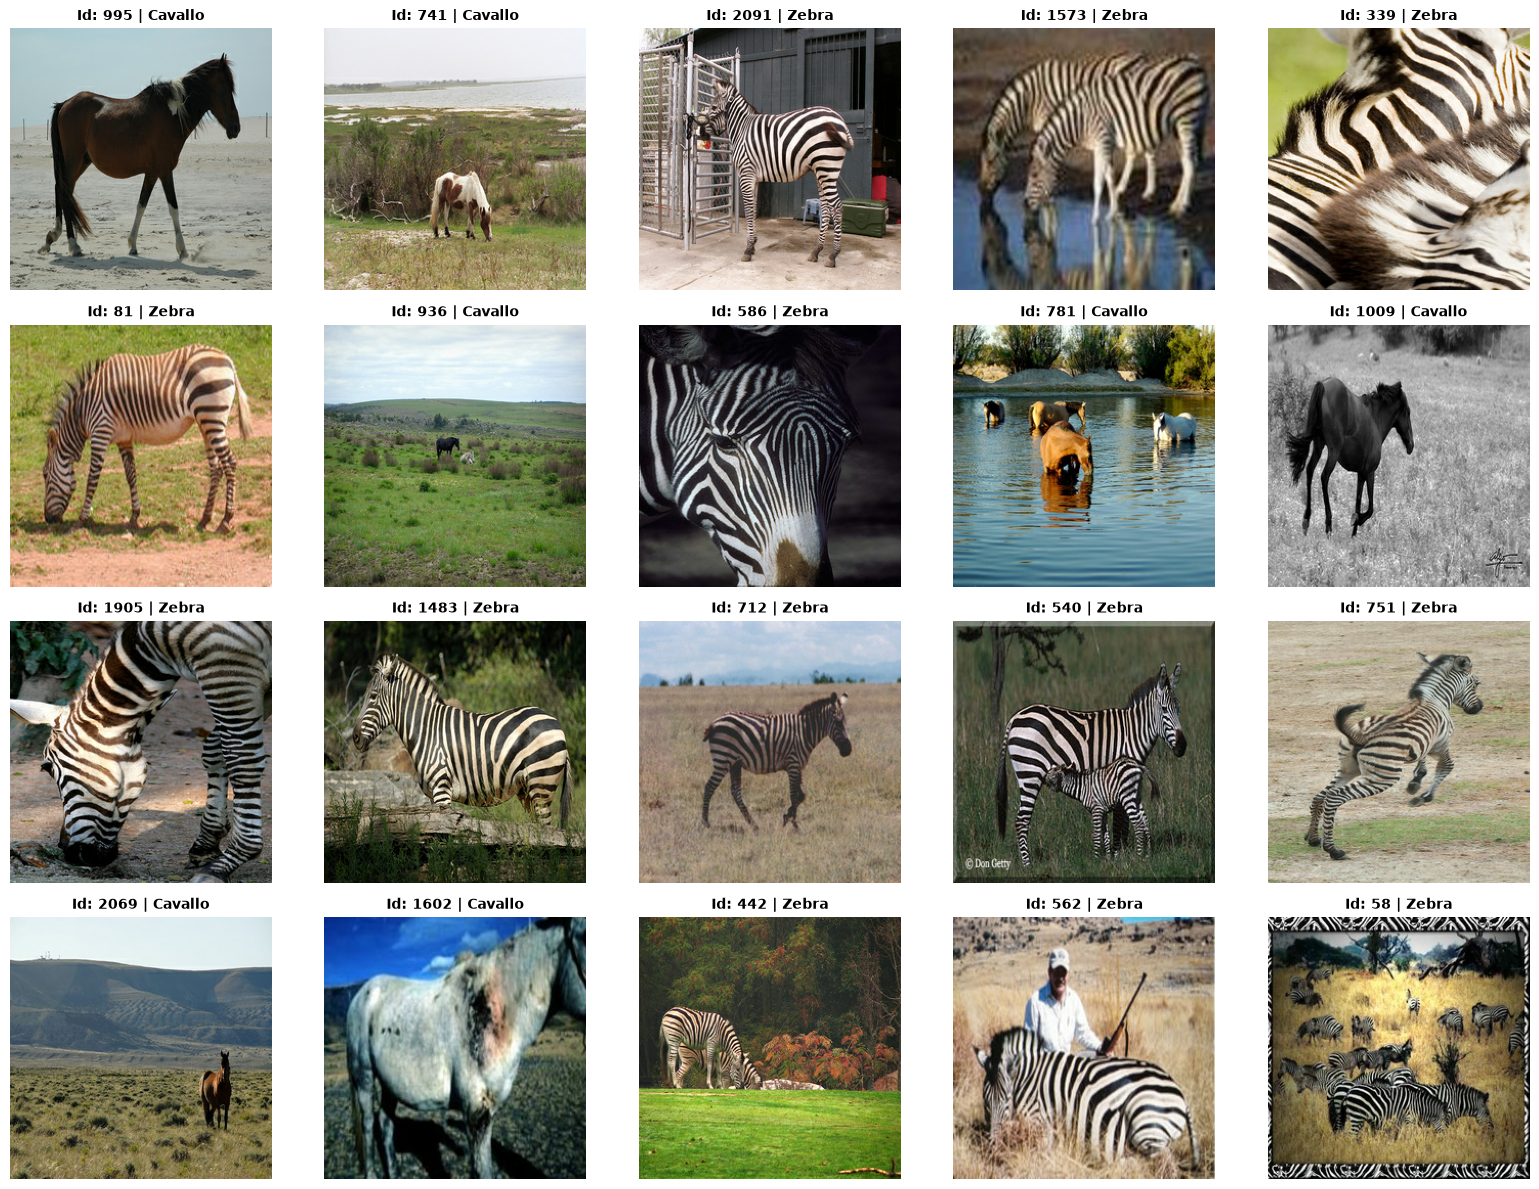

In [10]:
def mostraGrigliaImmagini(immagini, tag, num_immagini=20):
    # Configuriamo la griglia per il subplot (4 righe e 5 colonne = 20 immagini)
    righe = 4
    colonne = 5

    fig, axes = plt.subplots(righe, colonne, figsize=(16, 12))
    axes = axes.flatten()

    # Estraiamo degli indici casuali dal dataset per avere una panoramica vera
    # NON mettiamo il seed qui, così ogni volta che eseguiamo la cella vediamo immagini diverse
    indici_casuali = np.random.choice(len(immagini), num_immagini, replace=False)

    for i, idx in enumerate(indici_casuali):
        ax = axes[i]
        ax.imshow(immagini[idx])    # Mostra l'immagine all'indice casuale estratto

        # Convertiamo il tag numerico in testo leggibile [0 = Cavallo, 1 = Zebra]
        nome_classe = "Zebra" if tag[idx] == 1 else "Cavallo"

        # Titolo di ogni foto: indice originale e classe
        ax.set_title(f"Id: {idx} | {nome_classe}", fontsize=10, fontweight="bold")
        ax.axis("off")  # Rimuove i numeri dei pixel sui bordi

    plt.tight_layout()  # Ottimizza lo spazio tra le foto per evitare sovrapposizioni dei titoli
    plt.show()


# Eseguo la funzione passandole il training set
mostraGrigliaImmagini(immTrain, tagTrain)


---

### 4. Analisi Visiva Qualitativa (Variabilità Intra-classe e Rumore)

Visualizzando un campione casuale di 20 immagini si osserva un'elevatissima variabilità intra-classe e la presenza di "rumore" di fondo: oltre a fotografie in natura (da vicino e da lontano), sono presenti campioni eterogenei come dipinti, immagini stilizzate, accostamenti con esseri umani e soggetti su sfondo artificiale (es. nero uniforme).

Abbiamo quindi che:
1. La presenza di immagini artistiche e stilizzate impedisce alla rete di basarsi su scorciatoie banali (come la texture realistica del pelo). Il modello dovrà essere abbastanza profondo da saper catturare la struttura geometrica astratta dell'animale (silhouette, forma del muso, orecchie) ed è sensato introdurre diversi strati di **Convoluzione 2D**.
2. Data la presenza di questi "outliers" visivi, sarà fondamentale monitorare la perdita (Loss) durante l'addestramento e introdurre tecniche di regolarizzazione (come il **Dropout**) per evitare che il modello si focalizzi troppo sui dettagli di queste immagini specifiche, compromettendo la capacità di generalizzare.

---

## Costruzione del Modello Baseline
Questo primo modello funge da Baseline, mi serve a stabilire un punto di partenza e valutare i limiti della rete prima di ottimizzarla.


In [11]:
from keras import layers, models

# DEFINIZIONE DELL'ARCHITETTURA
initializeSeed()
baseline_model = models.Sequential([
    # --- LIVELLO DI INPUT & PREPROCESSING ---
    # Specifico la shape trovata nell'analisi precedente
    layers.Input(shape=(256, 256, 3)),
    layers.Rescaling(1./255),   # Normalizzo i pixel da [0, 255] a [0.0, 1.0]
    
    # --- PRIMA CONVOLUZIONE ---
    # Estrae le caratteristiche geometriche di basso livello (bordi, linee delle strisce)
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)), # Dimezza la dimensione spaziale (da 256x256 a 128x128)
    
    # --- SECONDA CONVOLUZIONE ---
    # Inizia a combinare le linee per riconoscere pattern più complessi
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)), # Dimezza ancora (da 128x128 a 64x64)
    
    # --- TERZA CONVOLUZIONE ---
    # Cattura strutture più grandi e astratte
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)), # Dimezza ancora (da 64x64 a 32x32)
    
    # --- APPIATTIMENTO E CLASSIFICAZIONE ---
    # Trasforma la matrice 3D in un vettore 1D
    layers.Flatten(),
    # Strato denso intermedio per elaborare le caratteristiche estratte
    layers.Dense(64, activation='relu'),
    
    # STRATO DI OUTPUT: attivazione Sigmoide per classificazione binaria
    # Restituisce un valore tra 0 (Cavallo) e 1 (Zebra)
    layers.Dense(1, activation='sigmoid')
])

# COMPILAZIONE DEL MODELLO
baseline_model.compile(
    optimizer='adam',                   # L'ottimizzatore standard più affidabile
    loss='binary_crossentropy',         # La funzione di loss per problemi di classificazione binaria
    metrics=['accuracy']                # La metrica concordata grazie al dataset bilanciato
)

# Mostriamo la struttura riassuntiva della rete
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,742,849 (14.28 MB)

 Trainable params: 3,742,849 (14.28 MB)

 Non-trainable params: 0 (0.00 B)


---

### 1. Scelta dei Blocchi Convoluzionali (3 strati Conv2D + MaxPooling)
* **Convoluzione 2D:** La rete è strutturata per estrarre informazioni a livelli di astrazione crescente:
  * **1° Strato (32 filtri):** Cattura dettagli geometrici elementari (bordi, linee, contrasti di colore).
  * **2° Strato (64 filtri):** Combina le linee del livello precedente per riconoscere texture e pattern complessi (es. il motivo a strisce della zebra).
  * **3° Strato (64 filtri):** Lavora su porzioni ampie dell'immagine per identificare strutture anatomiche astratte (silhouette, muso, orecchie).
* **MaxPooling2D:** Riduce progressivamente la dimensione spaziale dell'immagine (da 256x256 a 32x32), dimezzando i calcoli e costringendo la rete a concentrarsi solo sulle caratteristiche più rilevanti.

---

### 2. Perché NON è stato inserito il Padding (`padding='valid'`)?
Partendo da immagini 256x256 pixel, non c'è il rischio di "far sparire" il soggetto rimpicciolendolo leggermente a ogni convoluzione.
Nei dataset zoologici il focus (cavallo/zebra) è quasi sempre al centro. La perdita di qualche pixel sui bordi esterni elimina solo dettagli di sfondo irrilevanti (cielo, erba), riducendo il rumore.
Inoltre, permettere all'immagine di rimpicciolirsi naturalmente aiuta l'algoritmo a convergere più velocemente verso l'output finale.

---

### 3. Ruolo della Parte Finale (Flatten e Dense)
* **`Flatten`:** Agisce da "ponte", trasformando la griglia geometrica 3D prodotta dalle convoluzioni in un vettore piatto 1D (una lista di caratteristiche estratte).
* **`Dense(64)` (Il Classificatore):** Non guarda la foto, ma elabora logicamente la lista del Flatten. Esegue le associazioni (es. *"se ci sono strisce + forma di cavallo, allora è una zebra"*).
* **`Dense(1)` con Sigmoide:** Strato di output standard per la classificazione binaria. Sputa fuori un'unica probabilità tra 0 (Cavallo) e 1 (Zebra), associata alla funzione di loss `binary_crossentropy`.

---

### 4. Scelta della Funzione di Loss (Binary Crossentropy)
Per misurare l'errore del modello durante la fase di addestramento è stata scelta la `binary_crossentropy`. Questa funzione è matematicamente ideale per i problemi di classificazione binaria poiché penalizza in modo logaritmico le predizioni errate, andando a sanzionare pesantemente il modello quando è molto "sicuro" di una risposta che si rivela sbagliata. La funzione di costo minimizzata dall'algoritmo è:
$$Loss = \sum_{i=1}^{N} [-y_i \log(\hat{y}_i) - (1 - y_i) \log(1 - \hat{y}_i)]$$
Dove $N$ è il numero di immagini nel batch, $y_i$ è l'etichetta reale (0 o 1) e $\hat{y}_i$ è la probabilità predetta dalla sigmoide nell'ultimo strato.

---

### 5. L'Ottimizzatore Adam (Adaptive Moment Estimation)
L'ottimizzatore `adam` è stato preferito ai classici algoritmi di discesa del gradiente (come la SGD) per la sua efficienza numerica. Adam combina matematicamente i vantaggi di due grandezze fondamentali: il primo momento dei gradienti (che sfrutta l'inerzia delle direzioni passate per superare più facilmente i minimi locali) e il secondo momento dei gradienti (che adatta il learning rate in modo indipendente per ogni singolo parametro basandosi sulla stima della loro varianza). Questo garantisce una convergenza nettamente più rapida e stabile verso il minimo della funzione di Loss.

---

## Addestramento del Modello Baseline

In [12]:
import matplotlib.pyplot as plt

# CONFIGURAZIONE E AVVIO DELL'ADDESTRAMENTO
EPOCHS = 15
BATCH_SIZE = 32

print("Inizio addestramento del modello Baseline...\n")

# Salviamo l'addestramento dentro la variabile 'history_baseline' 
# per poter tracciare i grafici successivamente
history_baseline = baseline_model.fit(
    immTrain, tagTrain,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(immVal, tagVal),  # Monitoriamo i dati di validazione
    verbose=1                          # Mostra la barra di avanzamento per ogni epoca
)

print("\nAddestramento completato!")

Inizio addestramento del modello Baseline...

Epoch 1/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 54s 772ms/step - accuracy: 0.7852 - loss: 0.4210 - val_accuracy: 0.8647 - val_loss: 0.2977
Epoch 2/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 53s 796ms/step - accuracy: 0.8905 - loss: 0.2650 - val_accuracy: 0.8985 - val_loss: 0.2648
Epoch 3/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 54s 810ms/step - accuracy: 0.9098 - loss: 0.2261 - val_accuracy: 0.9060 - val_loss: 0.2361
Epoch 4/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 55s 823ms/step - accuracy: 0.9290 - loss: 0.1760 - val_accuracy: 0.9060 - val_loss: 0.2522
Epoch 5/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 60s 901ms/step - accuracy: 0.9436 - loss: 0.1402 - val_accuracy: 0.9248 - val_loss: 0.2572
Epoch 6/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.9577 - loss: 0.1074 - val_accuracy: 0.9135 - val_loss: 0.3791
Epoch 7/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 64s 952ms/step - accuracy: 0.9648 - loss: 0.0858 - val_accuracy: 0.8985 - val_loss: 0.5759
Epoch 8/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 58s 861ms/step -

In [13]:
import matplotlib.pyplot as plt

# Funzione per visualizzare la history
# Supporta sia un singolo oggetto history che un dizionario di oggetti history per il confronto
def showHistory(history_data, maxEpochs=None):
    # 1. Controllo dell'input: se non è un dizionario, lo trasformiamo in un dizionario con un solo elemento
    if not isinstance(history_data, dict):
        modelli_da_disegnare = {'Modello': history_data}
        confronto_multiplo = False
    else:
        modelli_da_disegnare = history_data
        confronto_multiplo = True

    # 2. Creazione della figura (Loss a sinistra, Accuracy a destra)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Palette di colori per i diversi modelli nel confronto
    colori_modelli = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd'] # Blu, Verde, Rosso, Viola

    # 3. Ciclo for su tutti i modelli passati in input
    for i, (nome_modello, hist) in enumerate(modelli_da_disegnare.items()):
        
        # Estraiamo il dizionario dei dati (gestisce sia l'oggetto History di Keras che dizionari puri)
        h_dict = hist.history if hasattr(hist, 'history') else hist
        epoche = range(1, len(h_dict['loss']) + 1)
        
        if not confronto_multiplo:
            # --- CASO 1: SINGOLO MODELLO (Colori classici fissi: Blu per Train, Rosso per Val)
            ax1.plot(epoche, h_dict['loss'], label='Training Loss', color='#1f77b4', marker='o', linewidth=2)
            if 'val_loss' in h_dict:
                ax1.plot(epoche, h_dict['val_loss'], label='Validation Loss', color='#d62728', marker='o', linewidth=2)

            ax2.plot(epoche, h_dict['accuracy'], label='Training Accuracy', color='#1f77b4', marker='o', linewidth=2)
            if 'val_accuracy' in h_dict:
                ax2.plot(epoche, h_dict['val_accuracy'], label='Validation Accuracy', color='#d62728', marker='o', linewidth=2)
        else:
            # --- CASO 2: CONFRONTO MULTIPLO (Un colore per modello: Continua=Train, Tratteggiata=Val)
            colore_corrente = colori_modelli[i % len(colori_modelli)]
            
            # Grafico della Loss
            ax1.plot(epoche, h_dict['loss'], label=f'{nome_modello} (Train)', color=colore_corrente, linestyle='-', linewidth=2)
            if 'val_loss' in h_dict:
                ax1.plot(epoche, h_dict['val_loss'], label=f'{nome_modello} (Val)', color=colore_corrente, linestyle='--', marker='none', linewidth=1.5)
            
            # Grafico dell'Accuracy
            ax2.plot(epoche, h_dict['accuracy'], label=f'{nome_modello} (Train)', color=colore_corrente, linestyle='-', linewidth=2)
            if 'val_accuracy' in h_dict:
                ax2.plot(epoche, h_dict['val_accuracy'], label=f'{nome_modello} (Val)', color=colore_corrente, linestyle='--', marker='none', linewidth=1.5)

    # 4. Formattazione e dettagli estetici dei grafici
    ax1.set_title('Andamento della Loss', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Epoca', fontsize=11)
    ax1.set_ylabel('Loss', fontsize=11)
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1.legend(fontsize=10, loc='upper right')

    ax2.set_title('Andamento dell\'Accuracy', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Epoca', fontsize=11)
    ax2.set_ylabel('Accuracy', fontsize=11)
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.legend(fontsize=10, loc='lower right')

    plt.tight_layout()
    plt.show()


Visualizzazione della history del modello Baseline...


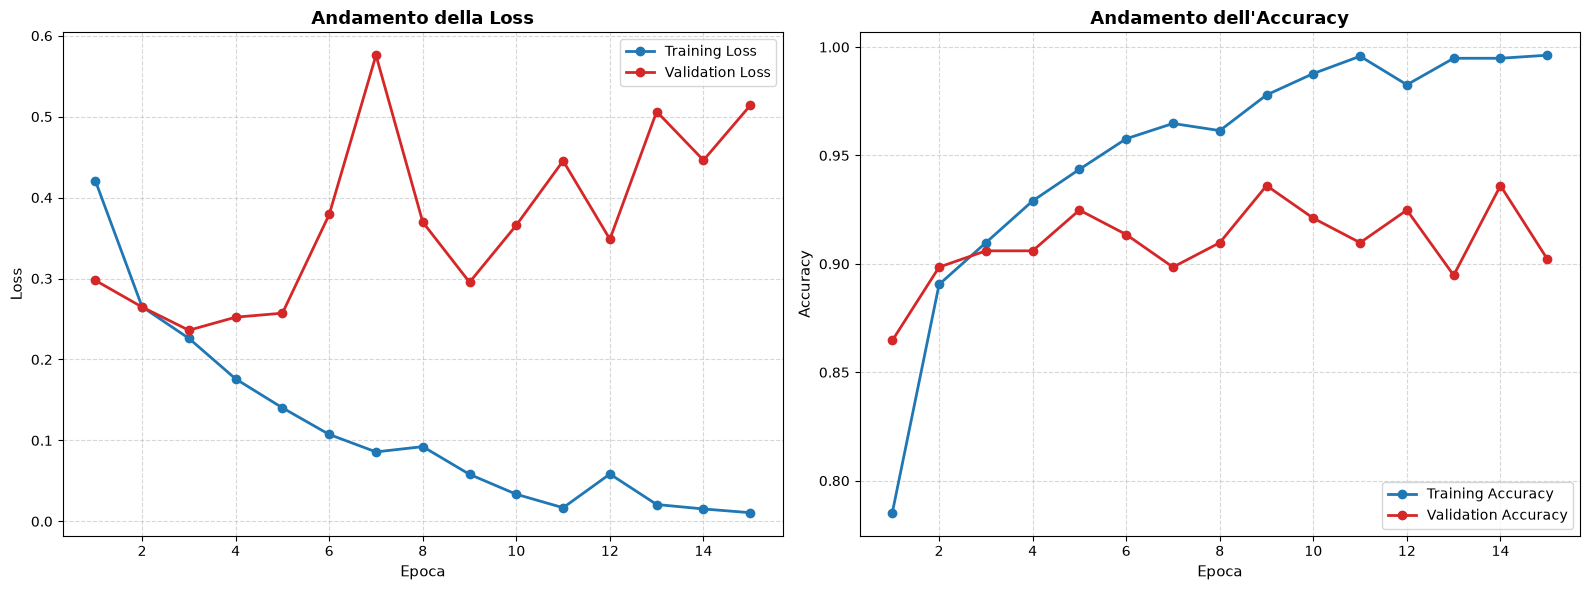

In [14]:
print("\nVisualizzazione della history del modello Baseline...")
showHistory(history_baseline, maxEpochs=15)  # Visualizza la history del modello Baseline con un massimo di 15 epoche

## Analisi delle Performance e Diagnosi (Modello Baseline)

I grafici di addestramento mostrano in modo evidente il fenomeno dell'**Overfitting** a partire dall'epoca 4.

### 1. Analisi del Grafico della Loss
La *Training Loss* (blu) abbatte l'errore costantemente tendendo a 0. Al contrario, la *Validation Loss* (rossa) scende fino all'epoca 3, per poi invertire la rotta e risalire.

Dunque, dall'epoca 4 in poi, la rete smette di imparare caratteristiche generali e inizia a "memorizzare" il rumore e i dettagli specifici del set di addestramento, riducendo la sua capacità di valutare dati nuovi.

### 2. Analisi del Grafico della Accuracy
La *Training Accuracy* viaggia spedita verso la perfezione, sfiorando il **99%** (`0.99`). La *Validation Accuracy*, invece, dall'epoca 4 si stabilizza con forti oscillazioni intorno al 90-94%.

La vistosa apertura a "forbice" tra le due curve conferma l'overfitting. Il modello è estremamente efficiente sui dati già visti, ma fallisce nel generalizzare con la stessa precisione sui dati di validazione. Questo significa che il modello ha imparato a memoria i dati di addestramente invece di estrarne le caratteristiche fondamentali per classificare correttamente le immagini.

---

### Strategia di Ottimizzazione per il Modello Successivo
L'analisi della baseline dimostra che l'architettura convoluzionale ha una buona capacità di calcolo (esprime un'ottima accuratezza sul train), ma va severamente regolata. Per curare questo overfitting, costruiamo altri 3 modelli introducendo il **Dropout**, che consiste nel spegnere casualmente dei neuroni durante il train ed evita il fenomeno della co-adaptation.

Confronteremo questi 3 modelli utilizzando gli iperparametri standard. Una volta scelto il modello migliore introdurremo un'ulteriore contromisura per l'overfitting, ovvero l'**Early Stopping**.

---

## Confronto tra le Architetture Baseline dei Nuovi modelli (iperparametri standard)

In questa fase alleniamo i tre nuovi modelli utilizzando gli stessi iperparametri ( Dropout a 0.5, Learning Rate a 0.001 e Batch Size a 32) per mettere a confronto tre diverse filosofie di struttura:

1. **Model 2 (Baseline Complessa):** 3 strati convoluzionali ad alta capacità (32, 64, 64 filtri). Avendo immagini grandi (256x256), rischia di accumulare troppi parametri nel livello *Flatten*, facilitando l'overfitting.
2. **Model 3 (Filosofia Leggera):** 3 strati convoluzionali ma con la metà dei filtri (16, 32, 32). Riduce la capacità della rete per impedirle di memorizzare i dettagli geometrici.
3. **Model 4 (Profondo ma Leggero):** Aggiungiamo un 4° strato convoluzionale mantenendo pochi filtri. La profondità aiuta a capire pattern più complessi e, rimpicciolendo ulteriormente l'immagine prima del *Flatten*, dimezza i parametri di connessione finali.

---

### Analisi Grafica

Dall'analisi delle curve di **Loss** e **Accuracy** andremo a verificare:

* **La "Forbice" dell'Overfitting:** Se e quando la *Validation Loss* ricomincia a salire mentre la *Training Loss* continua a scendere. Il modello con il distacco minore tra le due linee è quello che generalizza meglio.
* **Il Punto di Minimo:** Quale modello tocca la *Validation Loss* più bassa in assoluto (indica la massima precisione su immagini mai viste).
* **Velocità e Stabilità:** Se le curve scendono in modo fluido o se mostrano troppi sbalzi e oscillazioni.

L'obiettivo è scegliere l'architettura migliore tra le tre per poi procedere all'ottimizzazione fine degli iperparametri (Dropout e Learning Rate) **solo** sul modello vincitore. La Bath Size verrà lasciata fissa a 32 per questioni ti tempo e costo computazionale (volendo si potrebbero testare i modelli scegliendo come Batch Size 64).

In [15]:
from tensorflow.keras import layers, models

### DEFINIZIONE DELLE ARCHITETTURE BASELINE ###

# --- MODEL 2: Baseline classica ad alta capacità ---
initializeSeed() # Resetta i pesi iniziali
model2 = models.Sequential([
    layers.Input(shape=(256, 256, 3)),
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(1, activation='sigmoid')
])

# --- MODEL 3: Filosofia "Leggera" (Riduzione dei parametri) ---
initializeSeed()
model3 = models.Sequential([
    layers.Input(shape=(256, 256, 3)),
    layers.Rescaling(1./255),
    
    # Ridotto il numero di filtri per limitare la capacità di memorizzazione
    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(1, activation='sigmoid')
])

# --- MODEL 4: Filosofia "Profonda ma Leggera" (4 Strati di Convoluzione) ---
initializeSeed()
model4 = models.Sequential([
    layers.Input(shape=(256, 256, 3)),
    layers.Rescaling(1./255),
    
    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Permette di estrarre feature più astratte e dimezza la dimensione del Flatten
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(1, activation='sigmoid')
])


### COMPILAZIONE DEI MODELLI (Parametri standard) ###
# Compiliamo tutti i modelli con la configurazione di default di Adam (LearningRate=0.001)

model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model4.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

### ADDESTRAMENTO DELLE BASELINE ###

EPOCHS = 30
BATCH_SIZE = 32

print("Addestramento in corso: Model 2...")
history_model2 = model2.fit(
    immTrain, tagTrain,
    epochs=EPOCHS,             
    batch_size=BATCH_SIZE,
    validation_data=(immVal, tagVal),
    verbose=0
)
print("Addestramento completato: Model 2!")

print("\nAddestramento in corso: Model 3...")
history_model3 = model3.fit(
    immTrain, tagTrain,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(immVal, tagVal),
    verbose=0
)
print("Addestramento completato: Model 3!")

print("\nAddestramento in corso: Model 4...")
history_model4 = model4.fit(
    immTrain, tagTrain,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(immVal, tagVal),
    verbose=0
)
print("Addestramento completato: Model 4!")

Addestramento in corso: Model 2...
Addestramento completato: Model 2!

Addestramento in corso: Model 3...
Addestramento completato: Model 3!

Addestramento in corso: Model 4...
Addestramento completato: Model 4!


In [16]:
import io
from IPython.display import display, HTML

def get_summary_str(model):
    # Cattura l'output testuale del summary di Keras
    stream = io.StringIO()
    model.summary(print_fn=lambda x: stream.write(x + '\n'))
    return stream.getvalue()

# Estrae i tre testi
summary2 = get_summary_str(model2) if 'model2' in locals() else "Model 2 non trovato"
summary3 = get_summary_str(model3) if 'model3' in locals() else "Model 3 non trovato"
summary4 = get_summary_str(model4) if 'model4' in locals() else "Model 4 non trovato"

# Costruisce la struttura HTML con i CSS per affiancarli
html_layout = f"""
<div style="display: flex; justify-content: space-between; font-family: monospace; font-size: 10px; line-height: 1.2;">
    <div style="flex: 1; margin-right: 15px; border-right: 1px dashed #ccc; padding-right: 10px;">
        <h3 style="text-align: center; color: #2c3e50;">MODELLO 2 (Baseline complessa)</h3>
        <pre style="white-space: pre-wrap; font-size: 10px;">{summary2}</pre>
    </div>
    <div style="flex: 1; margin-right: 15px; border-right: 1px dashed #ccc; padding-right: 10px;">
        <h3 style="text-align: center; color: #2c3e50;">MODELLO 3 (Filosofia Leggera)</h3>
        <pre style="white-space: pre-wrap; font-size: 10px;">{summary3}</pre>
    </div>
    <div style="flex: 1;">
        <h3 style="text-align: center; color: #2c3e50;">MODELLO 4 (Profondo ma Leggero)</h3>
        <pre style="white-space: pre-wrap; font-size: 10px;">{summary4}</pre>
    </div>
</div>
"""

display(HTML(html_layout))

### Analisi Comparativa delle Architetture e dei Parametri

Il confronto diretto dei nodi strutturali delle tre reti permette di quantificare matematicamente l'efficacia della strategia applicata nel **Modello 4** rispetto alla **Baseline (Modello 2)**:

| Metrica Strutturale | Modello 2 (Baseline Complessa) | Modello 3 (Filosofia Leggera) | Modello 4 (Profondo ma Leggero) |
| :--- | :---: | :---: | :---: |
| **Filtri Convoluzionali** | 3 Layer (32, 64, 64) | 3 Layer (16, 32, 32) | 4 Layer (16, 32, 32, 64) |
| **Dimensione al Flatten** | $30 \times 30 \times 64$ | $30 \times 30 \times 32$ | $14 \times 14 \times 64$ |
| **Connessioni al Layer Dense**| 57,600 | 28,800 | 12,544 |
| **Parametri Addestrabili** | 3,742,849 | 1,857,665 | 835,777 |

Da questa tabella possiamo osservare:

1. **Il "Collo di Bottiglia" tra Convoluzione e Classificazione:** La maggior parte dei parametri di una CNN si concentra nel passaggio tra l'ultimo strato convoluzionale e il primo strato `Dense`. Nel Modello 2, l'assenza di un quarto blocco di riduzione porta a un vettore di ben **57.600 elementi**, generando milioni di parametri che sovraccaricano il modello. 
Nel Modello 4, l'aggiunta di un quarto strato di `MaxPooling2D` riduce la risoluzione spaziale da $30 \times 30$ a $14 \times 14$ prima del `Flatten`. Questo riduce drasticamente gli input per il layer `Dense` (da 57.600 a 12.544), forzando la rete a lavorare con una rappresentazione dell'immagine più sintetica e astratta.

2. **Controllo della Complessità del Modello:** Il Modello 4 segue un principio fondamentale: *aumentare la profondità per estrarre feature più astratte, riducendo però la capacità totale di memorizzazione*. Avendo tagliato i parametri addestrabili (passando da 3.7 milioni a circa 835 mila, una riduzione di oltre il 77%), la rete ha meno "spazio" per imparare a memoria le immagini del training set. 
Questa limitazione strutturale è il motivo per cui il Modello 4 soffre meno di overfitting rispetto alla Baseline: non potendo memorizzare i dati, la rete è costretta a "generalizzare", ovvero a imparare i tratti distintivi di cavalli e zebre che rimangono validi anche su immagini che non ha mai visto prima.


Confronto grafico delle tre architetture baseline:


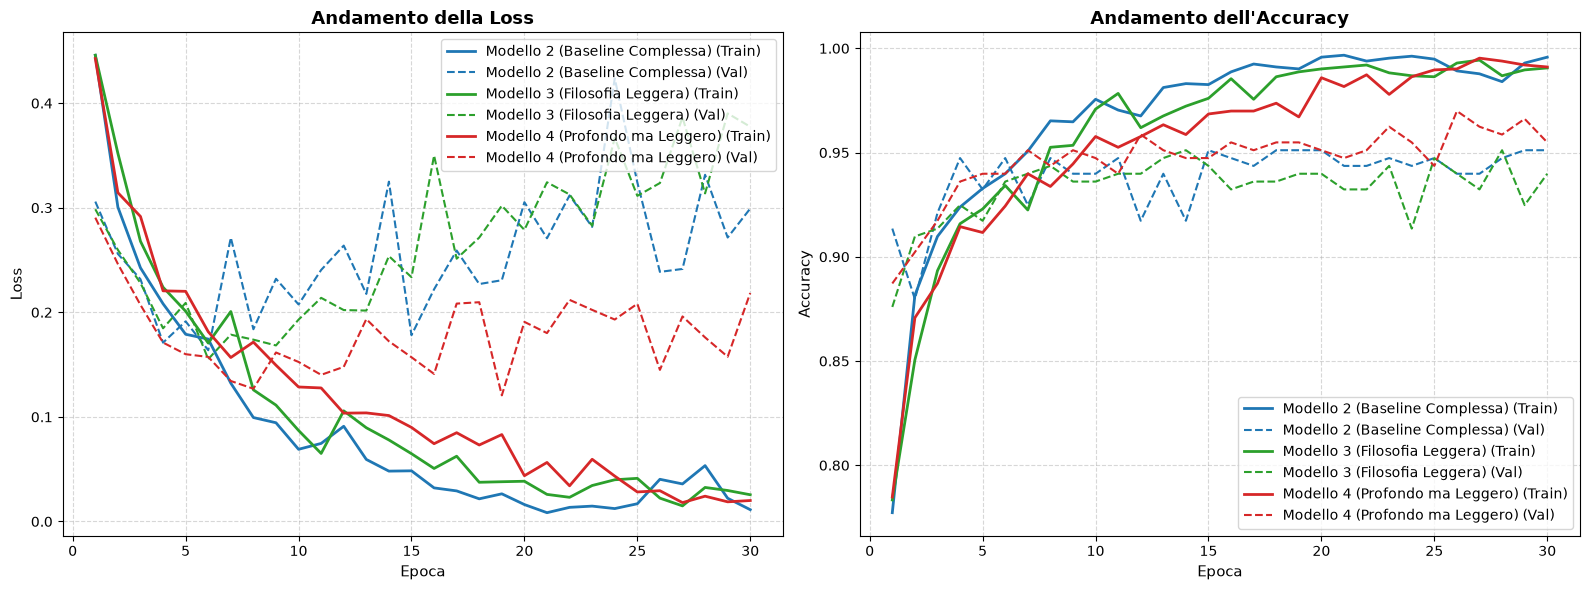

CONFRONTO QUANTITATIVO DELLE ARCHITETTURE BASELINE:


,Modello,Miglior Epoca,Train Loss,Train Accuracy,Val Loss,Val Accuracy
2,Modello 4 (Profondo ma Leggero),19,0.083104,0.967105,0.120596,0.954887
1,Modello 3 (Filosofia Leggera),6,0.170609,0.934211,0.155240,0.936090
0,Modello 2 (Baseline Complessa),6,0.174414,0.939850,0.163751,0.947368


In [17]:
import pandas as pd

### CONFRONTO GRAFICO DELLE HISTORIES ###

# Mettiamo le history dei tre modelli in un dizionario
baseline_histories = {
    'Modello 2 (Baseline Complessa)':   history_model2,
    'Modello 3 (Filosofia Leggera)':    history_model3,
    'Modello 4 (Profondo ma Leggero)':  history_model4
}

# Visualizza il confronto grafico delle tre baseline
print("Confronto grafico delle tre architetture baseline:")
showHistory(baseline_histories) 

dati_confronto = []

# Estraiamo automaticamente i valori nel punto di minimo val_loss per ciascuno
for nome_modello, hist in baseline_histories.items():
    # Trova l'epoca in cui la val_loss è stata la più bassa in assoluto
    best_idx = hist.history['val_loss'].index(min(hist.history['val_loss']))
    
    dati_confronto.append({
        'Modello': nome_modello,
        'Miglior Epoca': best_idx + 1,
        'Train Loss': hist.history['loss'][best_idx],
        'Train Accuracy': hist.history['accuracy'][best_idx],
        'Val Loss': hist.history['val_loss'][best_idx],
        'Val Accuracy': hist.history['val_accuracy'][best_idx]
    })

# Creiamo la tabella e ordiniamola dal migliore (Val Loss più bassa) al peggiore
df_baseline = pd.DataFrame(dati_confronto).sort_values(by='Val Loss', ascending=True)

print("CONFRONTO QUANTITATIVO DELLE ARCHITETTURE BASELINE:")
display(df_baseline)

## Analisi del Macro-Trend: Rumore Statistico vs Overfitting Reale

Come si evince dall'analisi quantitativa, l'algoritmo ha individuato il punto di minimo matematico della *Validation Loss* all'epoca 19. Tuttavia, un'ispezione visiva delle curve rivela che questo valore rappresenta un **falso minimo** dovuto al rumore statistico.

Nelle reti neurali, la valutazione sui mini-batch genera curve "seghettate". All'epoca 19, il modello ha sperimentato una temporanea fluttuazione favorevole. 

### Osservazione del Macro-Trend

Se si osserva il divario (Gap) tra *Training Loss* e *Validation Loss*, si nota che:
1. Fino all'**epoca 8**, le due curve scendono quasi parallelamente. Il modello sta imparando e generalizzando bene.
2. Dopo l'epoca 8, la *Validation Loss* si stabilizza e inizia a fluttuare, mentre la *Training Loss* continua a crollare verso lo zero. Il divario tra le due aumenta drasticamente.

Questo allargamento della "forbice" è la prova inequivocabile dell'inizio dell'**overfitting**. Per dimostrarlo visivamente, applichiamo una funzione di *smoothing* (media mobile esponenziale) alle curve, eliminando le fluttuazioni stocastiche e rivelando la vera tendenza del modello.

### Applicazione della Media Mobile Esponenziale (Smoothing)

Per isolare il macro-trend ed eliminare visivamente le fluttuazioni stocastiche causate dalla valutazione sui mini-batch, applichiamo alle curve una funzione matematica di *smoothing*. Nello specifico, utilizziamo una Media Mobile Esponenziale, che calcola il nuovo valore bilanciando l'osservazione corrente con lo storico precedente
$$S_t = \alpha S_{t-1} + (1 - \alpha) X_t$$
dove
* $X_t$ rappresenta il valore grezzo rilevato all'epoca corrente (Loss o Accuracy)
* $S_{t-1}$ è il valore lisciato calcolato all'epoca precedente
* $\alpha$ è il fattore di smorzamento (impostato nel nostro codice a `0.8`), che determina quanto peso dare alla storia passata rispetto al dato attuale.

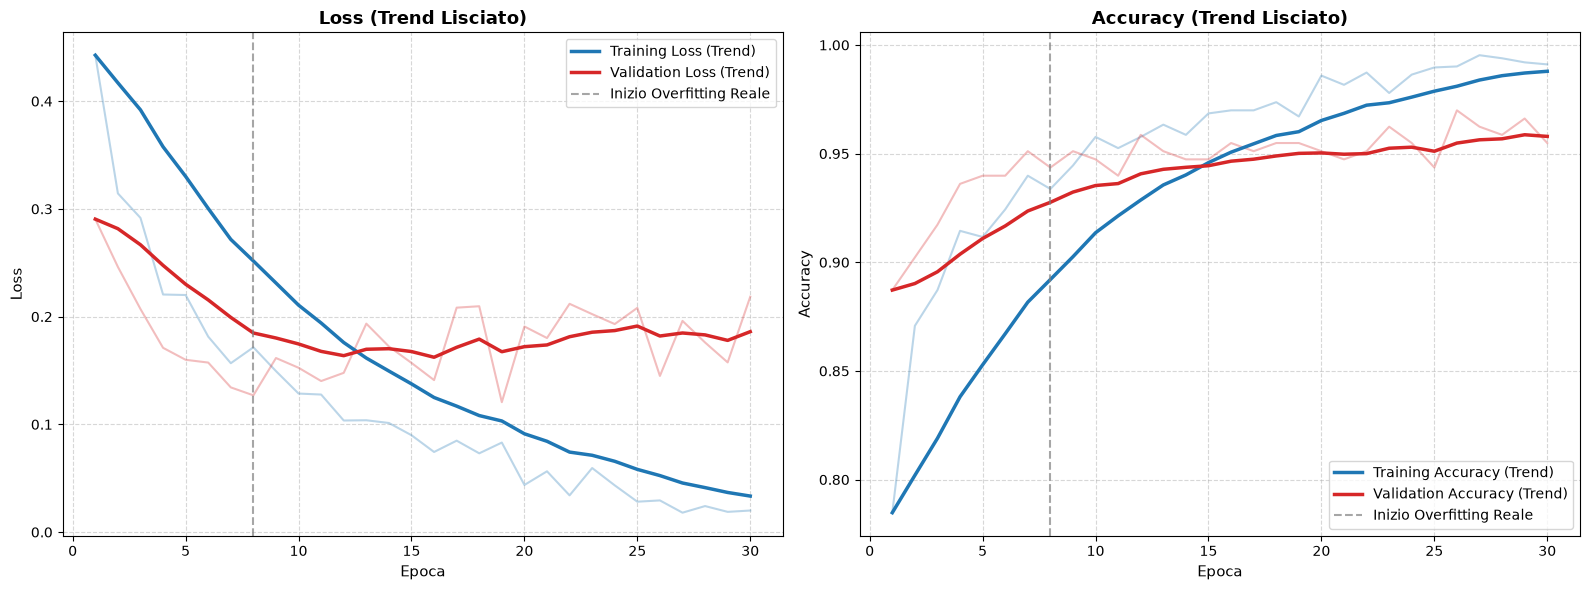

In [18]:
import matplotlib.pyplot as plt

# Funzione per lisciare la curva dei dati (Loss o Accuracy) usando una media mobile esponenziale
# factor: tra 0 e 1 (più è alto, più la linea è liscia. 0.8 è lo standard)
def smooth_curve(points, factor=0.8):
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            # Calcola la media tra il punto precedente e il nuovo punto
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points

# Funzione per visualizzare la history lisciata di un singolo modello
def showSmoothedHistory(history, factor=0.8):
    h_dict = history.history if hasattr(history, 'history') else history
    epoche = range(1, len(h_dict['loss']) + 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # --- GRAFICO LOSS ---
    # Linee originali (trasparenti per far vedere il rumore statistico)
    ax1.plot(epoche, h_dict['loss'], color='#1f77b4', alpha=0.3, linestyle='-')
    ax1.plot(epoche, h_dict['val_loss'], color='#d62728', alpha=0.3, linestyle='-')
    
    # Linee lisciate (il vero trend)
    ax1.plot(epoche, smooth_curve(h_dict['loss'], factor), label='Training Loss (Trend)', color='#1f77b4', linewidth=2.5)
    ax1.plot(epoche, smooth_curve(h_dict['val_loss'], factor), label='Validation Loss (Trend)', color='#d62728', linewidth=2.5)
    
    # Linea verticale per indicare l'epoca in cui inizia l'overfitting
    ax1.axvline(x=8, color='gray', linestyle='--', alpha=0.7, label='Inizio Overfitting Reale')
    
    ax1.set_title('Loss (Trend Lisciato)', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Epoca', fontsize=11)
    ax1.set_ylabel('Loss', fontsize=11)
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1.legend()

    # --- GRAFICO ACCURACY ---
    # Linee originali
    ax2.plot(epoche, h_dict['accuracy'], color='#1f77b4', alpha=0.3, linestyle='-')
    ax2.plot(epoche, h_dict['val_accuracy'], color='#d62728', alpha=0.3, linestyle='-')
    
    # Linee lisciate
    ax2.plot(epoche, smooth_curve(h_dict['accuracy'], factor), label='Training Accuracy (Trend)', color='#1f77b4', linewidth=2.5)
    ax2.plot(epoche, smooth_curve(h_dict['val_accuracy'], factor), label='Validation Accuracy (Trend)', color='#d62728', linewidth=2.5)
    
    ax2.axvline(x=8, color='gray', linestyle='--', alpha=0.7, label='Inizio Overfitting Reale')
    
    ax2.set_title('Accuracy (Trend Lisciato)', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Epoca', fontsize=11)
    ax2.set_ylabel('Accuracy', fontsize=11)
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.legend()

    plt.tight_layout()
    plt.show()

# Usa la funzione passandogli la history del Modello 4
showSmoothedHistory(history_model4)

### Inerzia e "Ritardo di Fase" nello Smoothing

Osservando il grafico lisciato, si nota che l'intersezione a "forbice" tra la curva di *Training* e quella di *Validation* sembra spostarsi in avanti (attorno all'epoca 12-15), nonostante l'algoritmo di Early Stopping abbia individuato l'inizio dell'overfitting all'epoca 8. 

Questa discrepanza visiva non è un errore, ma una conseguenza matematica diretta della Media Mobile Esponenziale, nota in teoria dei segnali come "Ritardo di Fase".

Riprendendo la formula dello smoothing:
$$S_t = \alpha S_{t-1} + (1 - \alpha) X_t$$

Il parametro $\alpha$ (impostato a $0.8$ come standard industriale) rappresenta l'"inerzia" del sistema. Poiché il dato passato ($S_{t-1}$) pesa per l'80%, quando la *Validation Loss* grezza ($X_t$) inizia improvvisamente a salire all'epoca 9 a causa dell'overfitting, il suo contributo attuale pesa solo per il 20%. La curva lisciata viene quindi matematicamente "trascinata verso il basso" dai valori ottimali accumulati nelle epoche precedenti.

Servono diverse epoche consecutive di errore in aumento affinché il termine $(1 - \alpha) X_t$ riesca a vincere l'inerzia accumulata e a far invertire visivamente la rotta alla curva lisciata. Scegliere un $\alpha$ più basso (es. $0.4$) ridurrebbe questo ritardo rendendo il grafico più reattivo ai cambiamenti, ma al costo di reintrodurre il rumore stocastico che si intendeva eliminare. 

Per questo motivo, l'algoritmo di ottimizzazione (Early Stopping) si affida rigorosamente al dato numerico grezzo per fermare l'addestramento nel punto esatto di generalizzazione ottimale, mentre lo smoothing viene utilizzato esclusivamente per rendere intellegibile il macro-trend nell'analisi a posteriori.


Addestramento combinazione: Drop_0.3_LR_0.001
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 10.
Epoche reali: 10 | Best Val Loss: 0.1562

Addestramento combinazione: Drop_0.3_LR_0.0001
Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 21.
Epoche reali: 21 | Best Val Loss: 0.1702

Addestramento combinazione: Drop_0.5_LR_0.001
Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 8.
Epoche reali: 8 | Best Val Loss: 0.1269

Addestramento combinazione: Drop_0.5_LR_0.0001
Epoch 30: early stopping
Restoring model weights from the end of the best epoch: 25.
Epoche reali: 25 | Best Val Loss: 0.1605

--- CLASSIFICA FINALE DEI MODELLI ---


,Configurazione,Dropout,Learning Rate,Best Epoch,Train Loss,Train Accuracy,Val Loss,Val Accuracy
2,Drop_0.5_LR_0.001,0.5,0.0010,8,0.171529,0.933741,0.126949,0.943609
0,Drop_0.3_LR_0.001,0.3,0.0010,10,0.124065,0.952068,0.156181,0.943609
3,Drop_0.5_LR_0.0001,0.5,0.0001,25,0.125674,0.953477,0.160493,0.943609
1,Drop_0.3_LR_0.0001,0.3,0.0001,21,0.140236,0.949248,0.170179,0.939850



Grafico dell'andamento del miglior modello in assoluto (Drop_0.5_LR_0.001):


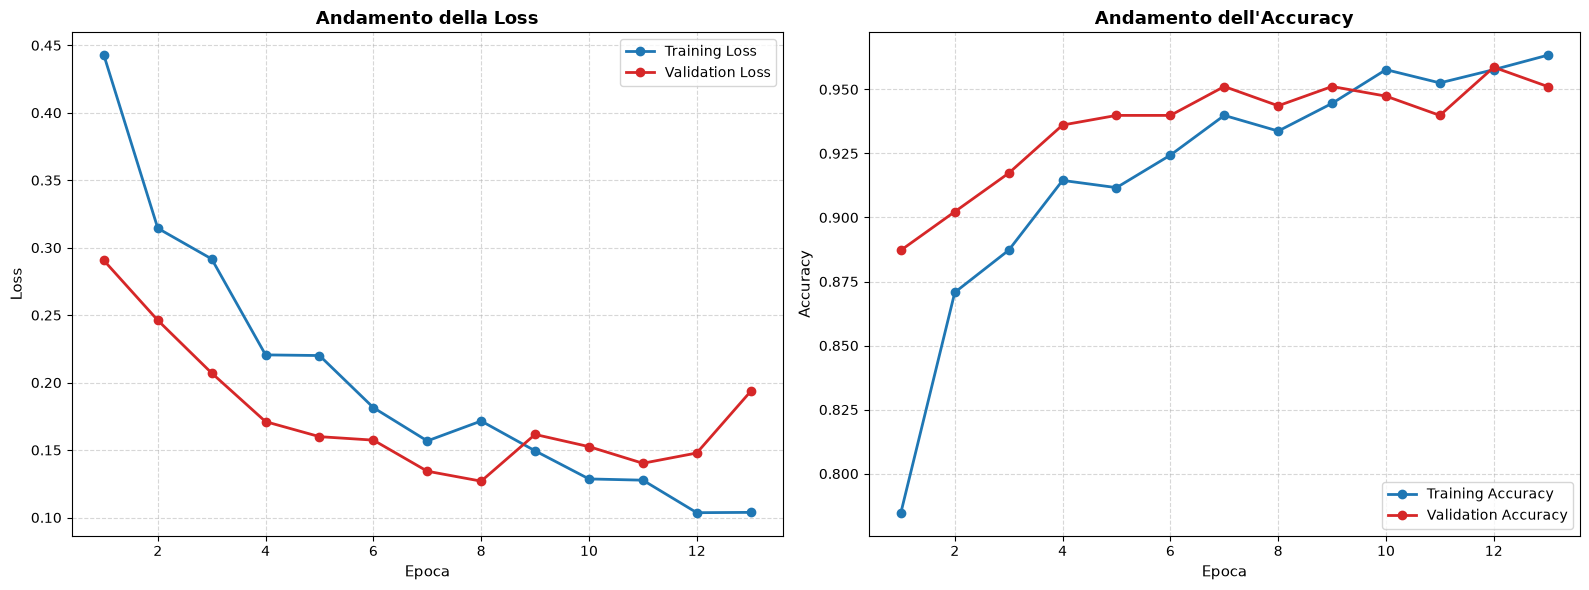

In [19]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Funzione per costruire il Model 4 con un parametro di dropout variabile
def createModel4(paramDropout):
    model = models.Sequential([
        layers.Input(shape=(256, 256, 3)),
        layers.Rescaling(1./255),
        
        layers.Conv2D(16, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(paramDropout), # Parametro variabile
        
        layers.Dense(1, activation='sigmoid')
    ])
    return model

### DEFINEZIONE DELLA GRIGLIA DI IPERPARAMETRI ###
# Scegliamo solo 2 valori ciascuno per fare in tutto 4 combinazioni veloci
dropout_grid = [0.3, 0.5]
lr_grid = [0.001, 0.0001]

MAX_EPOCHE = 30
lista_risultati = []

# Variabili di supporto per salvare il "vincitore assoluto" in memoria
best_val_loss = float('inf')
best_history = None
best_config_name = ""

### CICLO DI OTTIMIZZAZIONE (GRID SEARCH) ###
for d in dropout_grid:
    for lr in lr_grid:
        config_id = f"Drop_{d}_LR_{lr}"
        print(f"\nAddestramento combinazione: {config_id}")
        
        initializeSeed()
        model = createModel4(paramDropout=d)
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
        model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
        
        early_stop = callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=5, 
            restore_best_weights=True, 
            verbose=1
        )
        
        # Allena il modello
        history = model.fit(
            immTrain, tagTrain,
            epochs=MAX_EPOCHE,
            batch_size=32,
            validation_data=(immVal, tagVal), 
            callbacks=[early_stop], 
            verbose=0 # Teniamo la compilazione pulita senza stampare ogni epoca
        )
        
        # Estrae i valori migliori raggiunti (grazie a restore_best_weights)
        # Troviamo l'indice dell'epoca in cui la val_loss era minima
        best_epoch_idx = history.history['val_loss'].index(min(history.history['val_loss']))
        
        final_train_loss = history.history['loss'][best_epoch_idx]
        final_train_acc = history.history['accuracy'][best_epoch_idx]
        final_val_loss = history.history['val_loss'][best_epoch_idx]
        final_val_acc = history.history['val_accuracy'][best_epoch_idx]
        
        print(f"Epoche reali: {best_epoch_idx+1} | Best Val Loss: {final_val_loss:.4f}")
        
        # Salva i risultati per la tabella finale
        lista_risultati.append({
            'Configurazione': config_id,
            'Dropout': d,
            'Learning Rate': lr,
            'Best Epoch': best_epoch_idx + 1,
            'Train Loss': final_train_loss,
            'Train Accuracy': final_train_acc,
            'Val Loss': final_val_loss,
            'Val Accuracy': final_val_acc
        })
        
        # Verifica se questo modello è il migliore in assoluto visto finora
        if final_val_loss < best_val_loss:
            best_val_loss = final_val_loss
            best_history = history
            best_config_name = config_id
            # SALVATAGGIO FISICO: Salva il modello sul disco in formato standard di Keras
            model.save('miglior_modello4_ottimizzato.keras')

### CREAZIONE DELLA TABELLA REASSUNTIVA (PANDAS) ###
df_risultati = pd.DataFrame(lista_risultati)

# Ordiniamo la tabella in base alla Validation Loss più bassa (il migliore in alto)
df_risultati = df_risultati.sort_values(by='Val Loss', ascending=True)

print("\n--- CLASSIFICA FINALE DEI MODELLI ---")
display(df_risultati) 

### GRAFICO DELLA HISTORY DEL MODELLO VINCITORE ###
print(f"\nGrafico dell'andamento del miglior modello in assoluto ({best_config_name}):")
showHistory(best_history)

## Risultati della Grid Search: Ottimizzazione degli Iperparametri

Dall'analisi incrociata delle configurazioni, il modello vincitore risulta essere quello addestrato con **Dropout a 0.5** e **Learning Rate a 0.001**. Questa combinazione ha raggiunto la *Validation Loss* più bassa in assoluto (**0.1269**), stabilizzandosi rapidamente attorno all'epoca 8.

I dati estratti ci permettono di fare due importanti considerazioni sul comportamento della rete:

1. **L'impatto del Learning Rate:** Ridurre il learning rate a `0.0001` si è rivelata una scelta sub-ottimale. L'apprendimento è diventato troppo cauto e lento (richiedendo oltre 20 epoche per convergere), e l'algoritmo non è riuscito a trovare un punto di minimo migliore rispetto a quello trovato dal rate standard.
2. **L'impatto del Dropout:** Un livello di regolarizzazione più aggressivo (50% invece del 30%) ha giovato nettamente al modello. Disattivando metà dei neuroni del layer *Dense*, abbiamo impedito alla rete di memorizzare i pattern, forzandola a estrarre feature più robuste e abbassando così l'errore sul set di validazione.
3. **Conferma Empirica dell'Overfitting:**
L'osservazione visiva del macro-trend lisciato effettuata nella sezione precedente, che suggeriva l'inizio dell'overfitting attorno all'epoca 8, trova in questi dati una perfetta conferma numerica. Come si evince dalla tabella, l'algoritmo di *Early Stopping* (impostato per monitorare rigorosamente il minimo della `val_loss`) ha interrotto l'addestramento e ripristinato i pesi delle configurazioni ottimali (con Learning Rate a 0.001) esattamente alle epoche 8 e 10. Questo allineamento tra l'analisi grafica qualitativa e l'ottimizzazione quantitativa valida in modo definitivo la nostra diagnosi sul comportamento della rete.

In conclusione la configurazione ottimale coincide con i valori standard suggeriti dalla letteratura scientifica. Il modello definitivo (`model4`) verrà quindi finalizzato con questi parametri.

In [20]:
from tensorflow.keras.models import load_model

# Carica il modello ottimizzato salvato dalla Grid Search
modello_finale = load_model('miglior_modello4_ottimizzato.keras')

### VALUTAZIONE FINALE SUL TEST SET ###
print("Valutazione del Modello finale sul Test Set in corso...\n")
test_loss, test_accuracy = modello_finale.evaluate(immTest, tagTest, verbose=0)

print("-"*40)
print(f"RISULTATI SUL TEST SET")
print("-"*40)   
print(f"Loss sul Test Set:     {test_loss:.4f}")
print(f"Accuracy sul Test Set: {test_accuracy * 100:.2f}%")

Valutazione del Modello finale sul Test Set in corso...

----------------------------------------
RISULTATI SUL TEST SET
----------------------------------------
Loss sul Test Set:     0.1476
Accuracy sul Test Set: 94.01%


### Definizione Formale delle Metriche di Valutazione

Per valutare compiutamente le performance del modello ottimizzato su dati mai visti (Test Set), l'**Accuratezza** (percentuale globale di risposte corrette) non è sufficiente. In questo specifico scenario binario, dove assegniamo `0 = Cavallo` e `1 = Zebra`, andremo ad analizzare altre due metriche diagnostiche fondamentali, ricavabili dalla Matrice di Confusione:

* **Precisione (Precision):** Indica la proporzione di immagini classificate dal modello come "Zebre" che appartengono effettivamente a tale classe. Matematicamente è definita dal rapporto $\frac{VP}{VP + FP}$ (Veri Positivi sul totale delle predizioni positive). Una precisione elevata indica l'assenza di "falsi allarmi" (pochi cavalli scambiati per zebre).
* **Richiamo (Recall):** Misura la capacità della rete di individuare tutte le "Zebre" realmente presenti nel dataset. È definito dal rapporto $\frac{VP}{VP + FN}$ (Veri Positivi sul totale dei positivi reali). Un richiamo elevato garantisce che il modello "si faccia scappare" pochissimi esemplari della classe target (poche zebre scambiate per cavalli).

Procediamo quindi al calcolo computazionale di questi indicatori e alla generazione della Matrice di Confusione per la diagnosi finale.

Calcolo delle predizioni sul Test Set...
----------------------------------------
RISULTATI SUL TEST SET
----------------------------------------
Accuratezza (Accuracy):  94.01%
Precisione  (Precision): 97.14%
Richiamo    (Recall):    91.89%
----------------------------------------


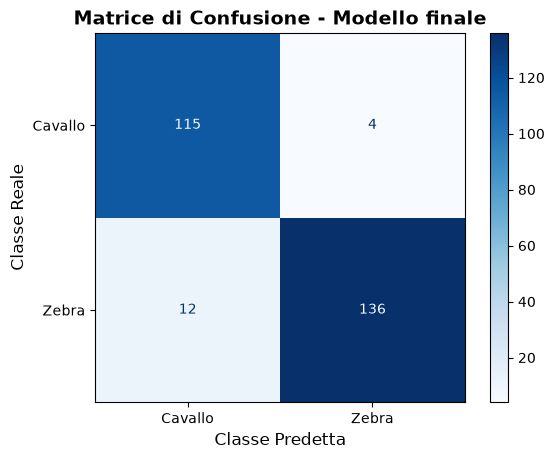

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

### GENERAZIONE DELLE PREDIZIONI ###
# Il modello restituisce una probabilità dovuta all'attivazione 'sigmoid'
print("Calcolo delle predizioni sul Test Set...")
probabilities = modello_finale.predict(immTest, verbose=0)

# Convertiamo le probabilità in classi binarie (0 o 1) con la soglia standard di 0.5
# Se la probabilità è > 0.5 diventa 1 (Zebra), altrimenti 0 (Cavallo)
predictions = (probabilities > 0.5).astype(int).flatten()
true_labels = np.array(tagTest).flatten()

### CALCOLO DELLE METRICHE ###
acc = accuracy_score(true_labels, predictions)
prec = precision_score(true_labels, predictions)
rec = recall_score(true_labels, predictions)

print("-" * 40)
print(f"RISULTATI SUL TEST SET")
print("-" * 40)
print(f"Accuratezza (Accuracy):  {acc * 100:.2f}%")
print(f"Precisione  (Precision): {prec * 100:.2f}%")
print(f"Richiamo    (Recall):    {rec * 100:.2f}%")
print("-" * 40)

### GENERAZIONE GRAFICA DELLA MATRICE DI CONFUSIONE ###
cm = confusion_matrix(true_labels, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Cavallo', 'Zebra'])

disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Matrice di Confusione - Modello finale', fontsize=14, fontweight='bold')
plt.xlabel('Classe Predetta', fontsize=12)
plt.ylabel('Classe Reale', fontsize=12)
plt.grid(False) 
plt.show()

Numero totale di errori trovati: 16


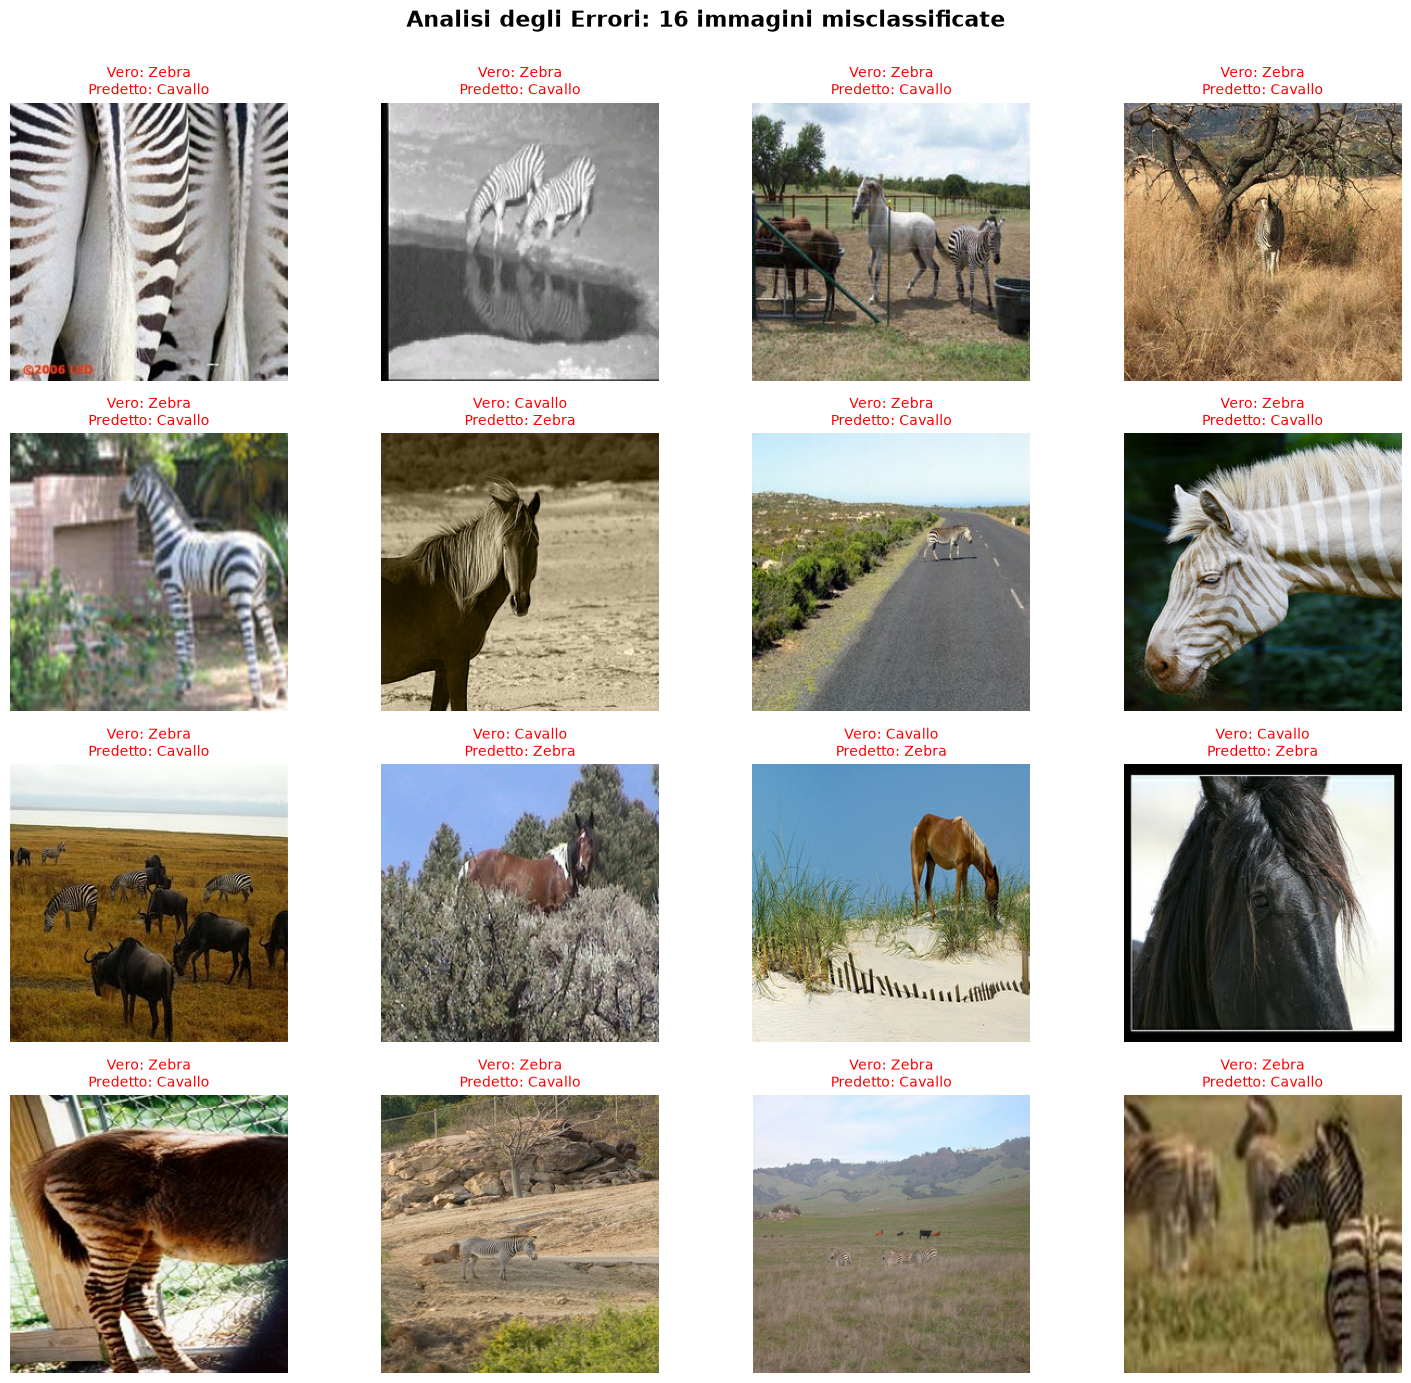

In [22]:
# Troviamo gli indici di dove il modello ha SBAGLIATO (dove la predizione è diversa dal tag reale)
misclassified_indices = np.where(predictions != true_labels)[0]

print(f"Numero totale di errori trovati: {len(misclassified_indices)}")

# Mappatura testuale per i titoli dei grafici
class_names = {0: "Cavallo", 1: "Zebra"}

# MOSTRIAMO LE IMMAGINI ERRATE
num_to_show = min(24, len(misclassified_indices)) 

plt.figure(figsize=(15, 20))
for i, idx in enumerate(misclassified_indices[:num_to_show]):
    plt.subplot(6, 4, i + 1)
    
    # Mostriamo l'immagine
    plt.imshow(immTest[idx])
    
    # Recuperiamo i testi delle etichette
    true_name = class_names[true_labels[idx]]
    pred_name = class_names[predictions[idx]]
    prob_val = probabilities[idx][0] if true_labels[idx] == 0 else 1 - probabilities[idx][0]
    
    # Titolo del subplot con i dettagli dell'errore
    plt.title(f"Vero: {true_name}\nPredetto: {pred_name}", color='red', fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.suptitle(f"Analisi degli Errori: {num_to_show} immagini misclassificate", fontsize=16, y=1.02, fontweight='bold')
plt.show()

## Risultati Finali e Analisi degli Errori

La valutazione sul Test Set del Modello 4 ottimizzato ha restituito risultati eccellenti, raggiungendo un'**Accuracy complessiva del 94.01%**.

Un dato particolarmente interessante emerge dall'analisi congiunta di **Precisione (97.14%)** e **Richiamo (91.89%)** e dalla relativa Matrice di Confusione. Notiamo infatti un'asimmetria negli errori:
* Il modello genera solo **4 Falsi Positivi** (Cavalli classificati come Zebre).
* Il modello genera **12 Falsi Negativi** (Zebre classificate come Cavalli).

Questa asimmetria indica che il modello ha identificato nel pattern a strisce ad alta frequenza la *feature* discriminante per la classe "Zebra". Di conseguenza, si comporta in modo conservativo: 
1. È estremamente difficile che la rete generi "allucinazioni" di strisce su manti a tinta unita, riducendo drasticamente i Falsi Positivi (alta Precisione).
2. Viceversa, qualora l'immagine della zebra presenti strisce sfocate, lontane o distorte (fenomeno accentuato dalle 4 operazioni di riduzione dimensionale del *MaxPooling*), la rete perde la sua feature principale e tende ad assegnare l'immagine alla classe visivamente più "generica", ovvero il Cavallo.

Questo comportamento dimostra che la regolarizzazione tramite Dropout al 50% ha funzionato, costringendo la rete ad apprendere feature robuste.

### Analisi Visiva delle Misclassificazioni

Osservando il plot delle 16 immagini classificate erroneamente (12 Falsi Negativi e 4 Falsi Positivi), è possibile escludere l'ipotesi di un bias sistematico legato al colore dello sfondo e individuare dinamiche di misclassificazione molto più specifiche, legate alla geometria e all'illuminazione dei soggetti:

1. **FALSI NEGATIVI: Scomparsa delle feature ad alta frequenza**

    Le 12 zebre classificate come cavalli presentano quasi tutte condizioni di illuminazione estreme (sovraesposizione solare, ombre marcate o forte lontananza). Dal punto di vista numerico, quando il contrasto nativo delle strisce viene alterato dalla luce, le successive 4 operazioni di riduzione dimensionale del *MaxPooling* fondono il pattern bianco/nero in un'unica mappa di attivazione omogenea. Persa la feature discriminante (la texture a strisce), il modello ricade conservativamente sulla classe visivamente più generica (il Cavallo). 
    A questo si aggiungono le immagini con soggetti multipli (es. zebre miste a bufali o a cavalli), dove l'output binario della sigmoide fatica a mediare tra feature contrastanti presenti nella stessa immagine.

2. **FALSI POSITIVI: Texture Bias e Inquadrature Parziali**

    I 4 cavalli classificati erroneamente come zebre offrono uno spunto di analisi sul funzionamento delle CNN. Un caso emblematico è il cavallo ritratto dietro una staccionata di legno: le assi verticali parallele generano un pattern visivo che i filtri convoluzionali interpretano matematicamente come "strisce", innescando l'attivazione della classe Zebra (fenomeno noto come *Texture Bias*). 
    Nei restanti 3 casi, i soggetti presentano inquadrature estremamente ravvicinate o tagliate (solo il muso o parte anteriore/superiore); l'assenza della forma globale dell'animale costringe la rete a valutare altre caratteristiche che generano falsi allarmi nell'estrazione delle feature.

## Conclusioni

L'obiettivo di questo progetto era costruire e ottimizzare una Rete Neurale Convoluzionale (CNN) per un task di classificazione binaria visiva (Cavalli vs. Zebre). Il percorso ha evidenziato le dinamiche classiche del Deep Learning:
1. **Identificazione e Regolarizzazione:** La baseline ad alta capacità ha mostrato un rapido overfitting. La transizione verso il Modello 4 (più profondo ma con parametri ridotti) e l'introduzione del Dropout al 50% hanno mitigato il problema, forzando la rete a estrarre feature robuste.
2. **Ottimizzazione Numerica:** La Grid Search ha confermato l'efficacia dell'ottimizzatore *Adam* con learning rate a $0.001$, permettendo all'Early Stopping di convergere nel punto di minimo matematico ottimale.

Il risultato sul Test Set (Accuracy **94.01%**, Precision **97.14%**) è molto buono. Il modello mostra un comportamento conservativo altamente desiderabile: richiede l'evidenza forte del pattern visivo ad alta frequenza (le strisce) per classificare un'immagine come Zebra, abbattendo quasi a zero i Falsi Positivi.

---

### Sviluppi Futuri e Limiti del Dataset
L'analisi manuale delle 16 misclassificazioni ha rivelato che la quasi totalità degli errori non è imputabile a un deficit matematico dell'architettura, bensì all'**Errore Irriducibile** generato da criticità intrinseche del dataset. Per superare l'attuale 94% di accuratezza, bisognerebbe concentrarsi sui dati piuttosto che sull'algoritmo:

1. **Data Cleaning e Problemi Mal Posti:** Sono emersi Falsi Negativi causati da immagini contenenti contemporaneamente sia zebre che altri animali (es. cavalli o bufali). Per un classificatore binario ($y \in \{0, 1\}$), un'immagine che appartiene visivamente a entrambe le classi rappresenta un problema matematicamente mal posto. Lo step futuro richiederebbe una pulizia manuale del dataset (rimozione degli outliers).
2. **Invarianza alle Inquadrature (Data Augmentation):** Alcuni Falsi Positivi derivano da inquadrature estremamente ravvicinate (solo muso o parti del cavallo). L'introduzione di tecniche di *Data Augmentation* (random crop, zoom e flipping spaziale) durante l'addestramento aiuterebbe il modello a riconoscere frammenti dell'animale.
3. **Degrado delle Feature (Luce e Risoluzione):** La causa principale dei Falsi Negativi risiede in condizioni di illuminazione estreme (sovraesposizione o zone d'ombra) che fondono i pixel del pattern zebrato in un colore omogeneo, distruggendo la *feature* alla base della convoluzione. In futuro, l'applicazione di filtri di normalizzazione del contrasto in fase di preprocessing potrebbe recuperare i gradienti perduti prima di passarli alla rete.